# Modelado

**Configuración del entorno.** Se importan las librerías y funciones auxiliares.

In [1]:
import os

RANDOM_SEED = 8
os.environ['PYTHONHASHSEED'] = str(RANDOM_SEED)
os.environ['TF_DETERMINISTIC_OPS'] = '1'

import time
import random
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt

In [2]:
import sys
sys.path.append('..')  # carpeta src/

from utils.sequences import to_dataset

**Constantes.** Se definen los parámetros constantes que se usarán.

In [3]:
# Modelado
WINDOW_SIZE = 4                 # semanas de contexto
TEST_SIZE, VAL_SIZE= 0.2, 0.2   # fracción reservada a test y validación
TARGET = 'M_281/320KG_E'        # categoría a predecir

# Entrenamiento
EPOCHS = 10_000
PATIENCE = 10
BATCH_SIZE = 16
LEARNING_RATE = 1e-4


**Reproducibilidad.** Se fijan las semillas y se fuerzan operaciones deterministas, de modo que dos entrenamientos con los mismos datos produzcan el mismo modelo.

In [4]:
def set_seed(seed: int = RANDOM_SEED):
    """Resultados reproducibles."""
    random.seed(seed)
    np.random.seed(seed)
    tf.random.set_seed(seed)
    tf.config.experimental.enable_op_determinism()

**Carga de los datos.** Se carga el conjunto de datos preprocesado, con una fila por semana y una columna por categoría *sex_weight_type* (creado en `preprocessing.ipynb`).

In [5]:
PATH_CLEAN_DATA = '../../data/BinefarBovinePriceCleaned.csv'

df_data = pd.read_csv(PATH_CLEAN_DATA, sep=';', index_col='date', parse_dates=True)
target_idx = df_data.columns.get_loc(TARGET)

n_rows, n_cols = df_data.shape
print(f'Dimensiones:\n- núm. registros: {n_rows}\n- núm. variables: {n_cols}')

Dimensiones:
- núm. registros: 619
- núm. variables: 32


**Construcción *datasets*.** Cada muestra de entrada contiene `WINDOW_SIZE` semanas consecutivas, y su salida es el precio de la categoría estudiada la semana siguiente.

In [6]:
x, y = to_dataset(
    df_data.to_numpy(),
    WINDOW_SIZE,
    target=target_idx
)
dates = df_data.index[WINDOW_SIZE:]  # fecha de cada muestra

print(f'x: {x.shape} (muestras, semanas, variables)')
print(f'y: {y.shape} (muestras, variables objetivo)')

x: (615, 4, 32) (muestras, semanas, variables)
y: (615, 1) (muestras, variables objetivo)


**Separación Train/Val/Test.**

In [7]:
def split(x: np.ndarray, y: np.ndarray, size: float) -> tuple[np.ndarray, ...]:
    """Divide `x` e `y` en dos bloques, el segundo contiene fracción `size`."""
    split = int(len(x) * (1 - size))
    return x[:split], x[split:], y[:split], y[split:]

In [8]:
x_train, x_test, y_train, y_test = split(x, y, TEST_SIZE)
x_train, x_val, y_train, y_val = split(x_train, y_train, VAL_SIZE)

n_train, n_val, n_test = len(x_train), len(x_val), len(x_test)
dates_val = dates[n_train : n_train + n_val]
dates_test = dates[n_train + n_val :]

print(f'Train: {n_train} muestras')
print(f'Val: {n_val} muestras')
print(f'Test: {n_test} muestras')

splits = {
    'Train': (x_train, y_train),
    'Val': (x_val, y_val),
    'Test': (x_test, y_test),
}

Train: 393 muestras
Val: 99 muestras
Test: 123 muestras


## Entrenamiento y evaluación

In [9]:
def train(model: tf.keras.Model, x_train, y_train, x_val, y_val):
    """Entrena con early stopping y devuelve historial."""
    early_stopping = tf.keras.callbacks.EarlyStopping(
        monitor='val_loss', patience=PATIENCE, restore_best_weights=True
    )
    model_history = model.fit(
        x_train, y_train,
        validation_data=(x_val, y_val),
        epochs=EPOCHS,
        batch_size=BATCH_SIZE,
        shuffle=False,
        callbacks=[early_stopping],
        verbose=0
    )
    return model_history.history


def predict(model: tf.keras.Model, x: np.ndarray) -> np.ndarray:
    """Devuelve las predicciones como array de NumPy."""
    return model.predict(x, verbose=0)

**Métricas de evaluación.** Se usarán tres métricas:

- **MAE** y **RMSE**, en las mismas unidades que el precio (€/kg).
- **Error máximo absoluto**, el mayor error cometido en una semana (€/kg).

Las métricas se calculan sobre los tres conjuntos (entrenamiento, validación y test). Comparar entrenamiento y validación permite detectar sobreajuste por memorización: el error en entrenamiento es significativamente menor que el de validación. El conjunto de test estima el rendimiento del modelo sobre datos nuevos.

In [10]:
def metrics(y_test: np.ndarray, y_pred: np.ndarray) -> dict[str, float]:
    """Métricas de evaluación."""
    err = y_pred - y_test
    return {
        'MAE': np.mean(np.abs(err)),
        'RMSE': np.sqrt(np.mean(err ** 2)),
        'Max error': np.max(np.abs(err)),
    }


def evaluate(
    predict_fun,
    splits: dict[str, tuple]
) -> dict[tuple[str, str], float]:
    """Métricas en cada subconjunto {(subconjunto, métrica): valor}."""
    return {
        (name, metric): value
        for name, (x, y) in splits.items()
        for metric, value in metrics(y, predict_fun(x)).items()
    }


def summary(results: dict) -> pd.DataFrame:
    """Tabla resumen: una fila por modelo y columnas agrupadas por subconjunto."""
    return pd.DataFrame(results).T.round(4)

**Gráficas de predicción.** Se comparan las predicciones con los valores reales y, en una segunda gráfica, las predicciones adelantadas una semana (*shifted*). Si la curva adelantada coincide con la real, el modelo se limita a repetir el precio de la semana anterior.

In [11]:
def plot_prediction(dates, y_true, y_pred, title: str = 'Prediction vs. real'):
    """Compara valores reales y predicciones a lo largo del tiempo."""
    plt.figure(figsize=(18, 6))
    plt.plot(dates, y_true, label='Real')
    plt.plot(dates, y_pred, label='Prediction')
    plt.title(title)
    plt.ylabel('Price (€/kg)')
    plt.legend()
    plt.show()


def plot_shifted(dates, y_true, y_pred):
    """Compara los valores reales con las predicciones adelantadas una semana."""
    plot_prediction(dates[:-1], y_true[:-1], y_pred[1:], title='Predictions shifted one week')

**Ejecución de un modelo.** Crear, entrenar y evaluar un modelo.

In [12]:
def run(name: str, build_fun):
    """Crea, entrena y evalúa un modelo. Guarda sus métrica en `results`."""
    set_seed()
    model = build_fun(x_train.shape[1:], y_train.shape[1])

    start = time.perf_counter()
    history = train(model, x_train, y_train, x_val, y_val)
    print(f'Tiempo de entrenamiento: {time.perf_counter() - start:.2f} s')

    pd.DataFrame(history).plot(xlabel='Epoch', ylabel='MSE', title=f'Training curves: {name}')
    plt.show()

    results[name] = evaluate(lambda x: predict(model, x), splits)
    display(summary({name: results[name]}))

    y_pred_test = predict(model, x_test)
    plot_prediction(dates_test, y_test, y_pred_test, title=f'Test: {name}')
    plot_shifted(dates_test, y_test, y_pred_test)

## Modelos

In [13]:
results = {}

**Modelo 1: LSTM.**

In [14]:
def build_lstm(input_shape: tuple[int, ...], output_dim: int) -> tf.keras.Model:
    inputs = tf.keras.layers.Input(shape=input_shape)
    # Capa LSTM
    lstm0 = tf.keras.layers.LSTM(32, activation='tanh', recurrent_activation='relu')(inputs)
    # Capa densa
    dense0 = tf.keras.layers.Dense(8, activation='relu')(lstm0)
    # Capa de salida
    output = tf.keras.layers.Dense(output_dim, activation='linear')(dense0)

    model = tf.keras.models.Model(inputs=inputs, outputs=output)
    model.compile(optimizer=tf.keras.optimizers.AdamW(learning_rate=LEARNING_RATE), loss='mse')
    return model

Tiempo de entrenamiento: 10.12 s


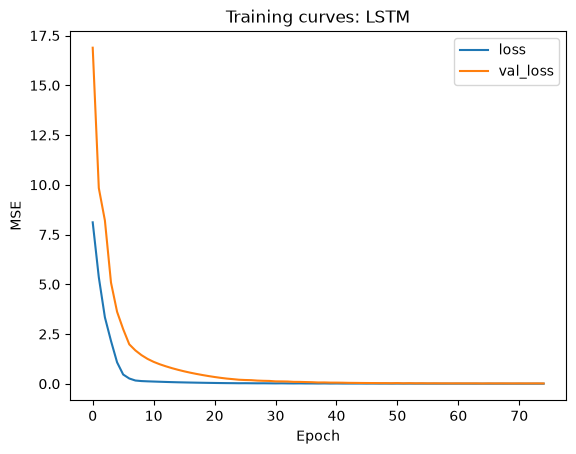

Train                       Val                      Test          \
         MAE    RMSE Max error     MAE    RMSE Max error     MAE    RMSE   
LSTM  0.0472  0.0736    0.7697  0.0911  0.1246     0.517  0.1789  0.2194   

                
     Max error  
LSTM    0.7423

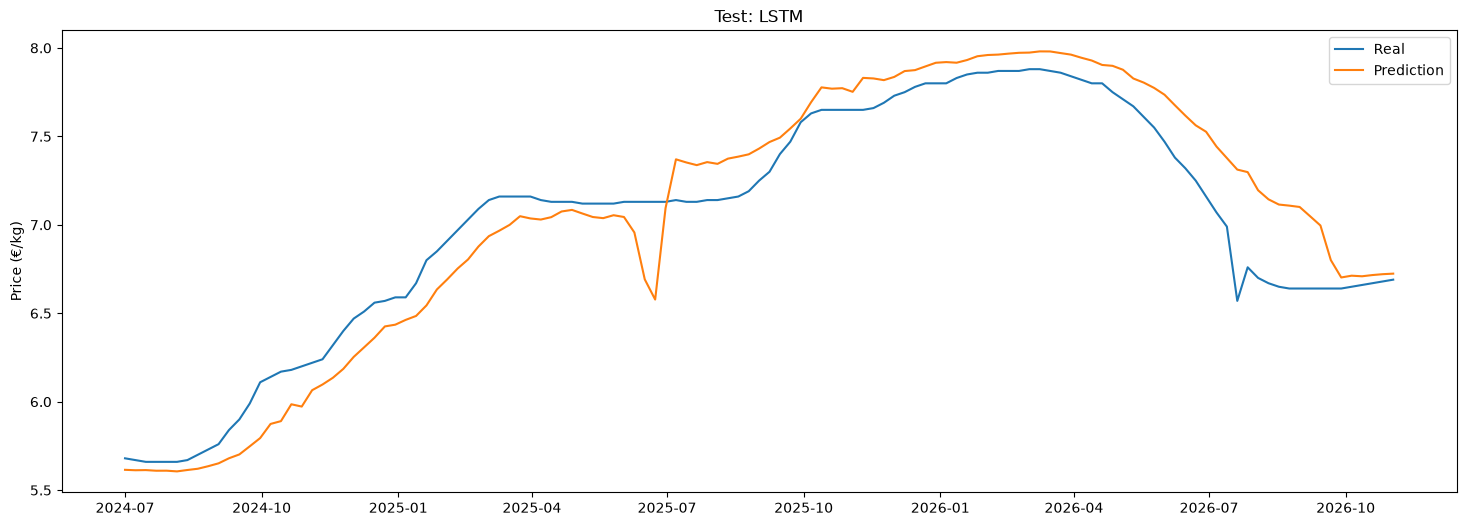

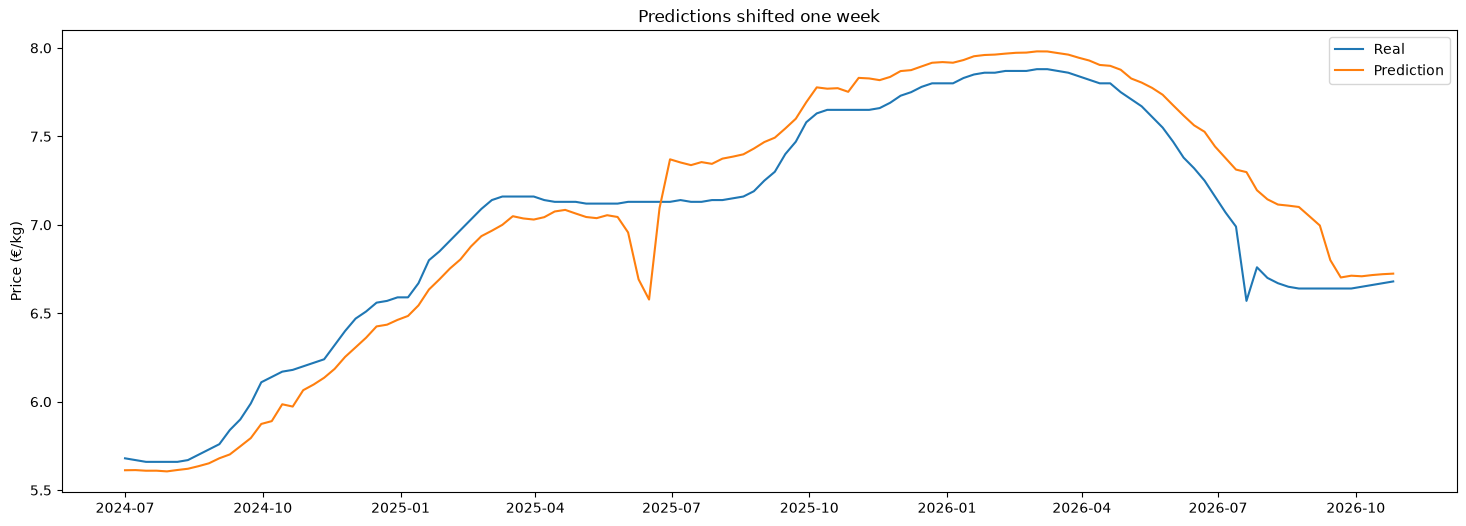

In [15]:
run('LSTM', build_lstm)

## Resumen

In [16]:
summary(results)

Train                       Val                      Test          \
         MAE    RMSE Max error     MAE    RMSE Max error     MAE    RMSE   
LSTM  0.0472  0.0736    0.7697  0.0911  0.1246     0.517  0.1789  0.2194   

                
     Max error  
LSTM    0.7423